In [81]:
import torch
import torch.nn as nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
import random
import torchvision.transforms.functional as F

In [82]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

Using device: cuda


In [83]:
batch_size = 512
learning_rate = 3e-4
n_epochs = 10
n_classes = 5
crop_size = 32

In [84]:
def random_90_rotation(img):
    angles = [0, 90, 180, 270]
    return F.rotate(img, angle=random.choice(angles))

transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.Lambda(random_90_rotation),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = datasets.ImageFolder(root=f"data/dataset_crops_sat/train_{crop_size}x{crop_size}", transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=6)

val_dataset = datasets.ImageFolder(root=f"data/dataset_crops_sat/val_{crop_size}x{crop_size}", transform=transform)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=6)

# test_dataset = datasets.ImageFolder(root=f"data/dataset_crops_{img_type}/test", transform=transform)
# test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=1)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)
# test_iterator = iter(test_loader)

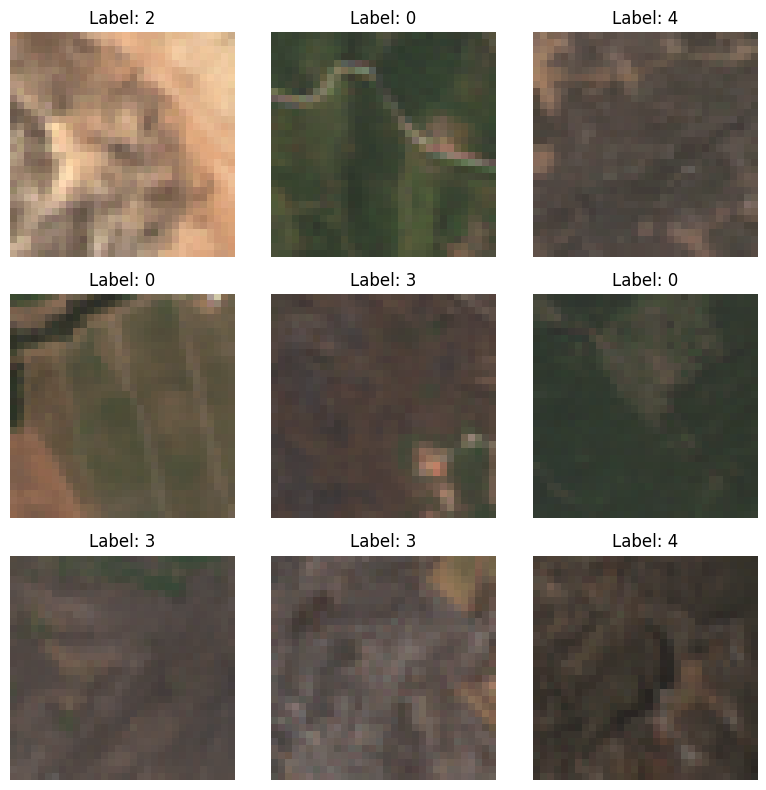

In [85]:
# Afficher une grille 3x3 d'exemples
fig, axes = plt.subplots(3, 3, figsize=(8, 8))
for i in range(3):
    for j in range(3):
        img, label = next(train_iterator)
        axes[i, j].imshow((img[0].permute(1, 2, 0).numpy() + 1)/2)
        axes[i, j].set_title(f"Label: {label[0]}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

In [86]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

resnet = resnet18(weights=None)

# # différentes couches du modèle
# for name, layer in model.named_children():
#     print(name, ":", layer)

# remplacer la dernière couche pour avoir le bon nombre de classe et pas les 1000 de ImageNet
in_features = resnet.fc.in_features
resnet.fc = nn.Linear(in_features, n_classes)

total_params = sum(p.numel() for p in resnet.parameters())
print(f"Total parameters in the resnet: {total_params/1e6:.6f} million")

Total parameters in the resnet: 11.179077 million


In [87]:
resnet = resnet.to(device)

# load the resnet parameters
checkpoint = torch.load("weights/resnet_sur_crops_sat_32x32_checkpoint10.pth")
resnet.load_state_dict(checkpoint["model_state_dict"])

resnet.eval()
resnet_minus_last_layer = nn.Sequential(*list(resnet.children())[:-1])

In [90]:
class SparseAutoencoder(nn.Module):

    def __init__(self, input_dim, hidden_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Sigmoid()
        )
        self.decoder = nn.Linear(hidden_dim, input_dim)

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat, z

In [101]:
def kl_divergence_bernouilli(rho, rho_hat):
    rho_hat = torch.clamp(rho_hat, min=1e-10, max=1 - 1e-10)  # éviter les log(0)
    return rho * torch.log(rho/rho_hat) + (1-rho) * torch.log((1-rho)/(1-rho_hat))

def sparsity_penalty(a, rho=0.1, beta=0.5):
    rho_hat = a.mean(dim=0)
    kl_div = kl_divergence_bernouilli(rho, rho_hat)
    return beta * torch.sum(kl_div)

In [107]:
sparse_auto_encoder = SparseAutoencoder(512, 100).to(device)
optimizer = torch.optim.AdamW(sparse_auto_encoder.parameters(), lr=learning_rate)
mse = nn.MSELoss()

train_loss_list, val_loss_list = [], []

In [108]:
def moving_average(x, w=10):
    smoothed = []
    for i in range(len(x)):
        start = max(0, i - w + 1)
        window = x[start:i+1]
        smoothed.append(sum(window) / len(window))
    return smoothed

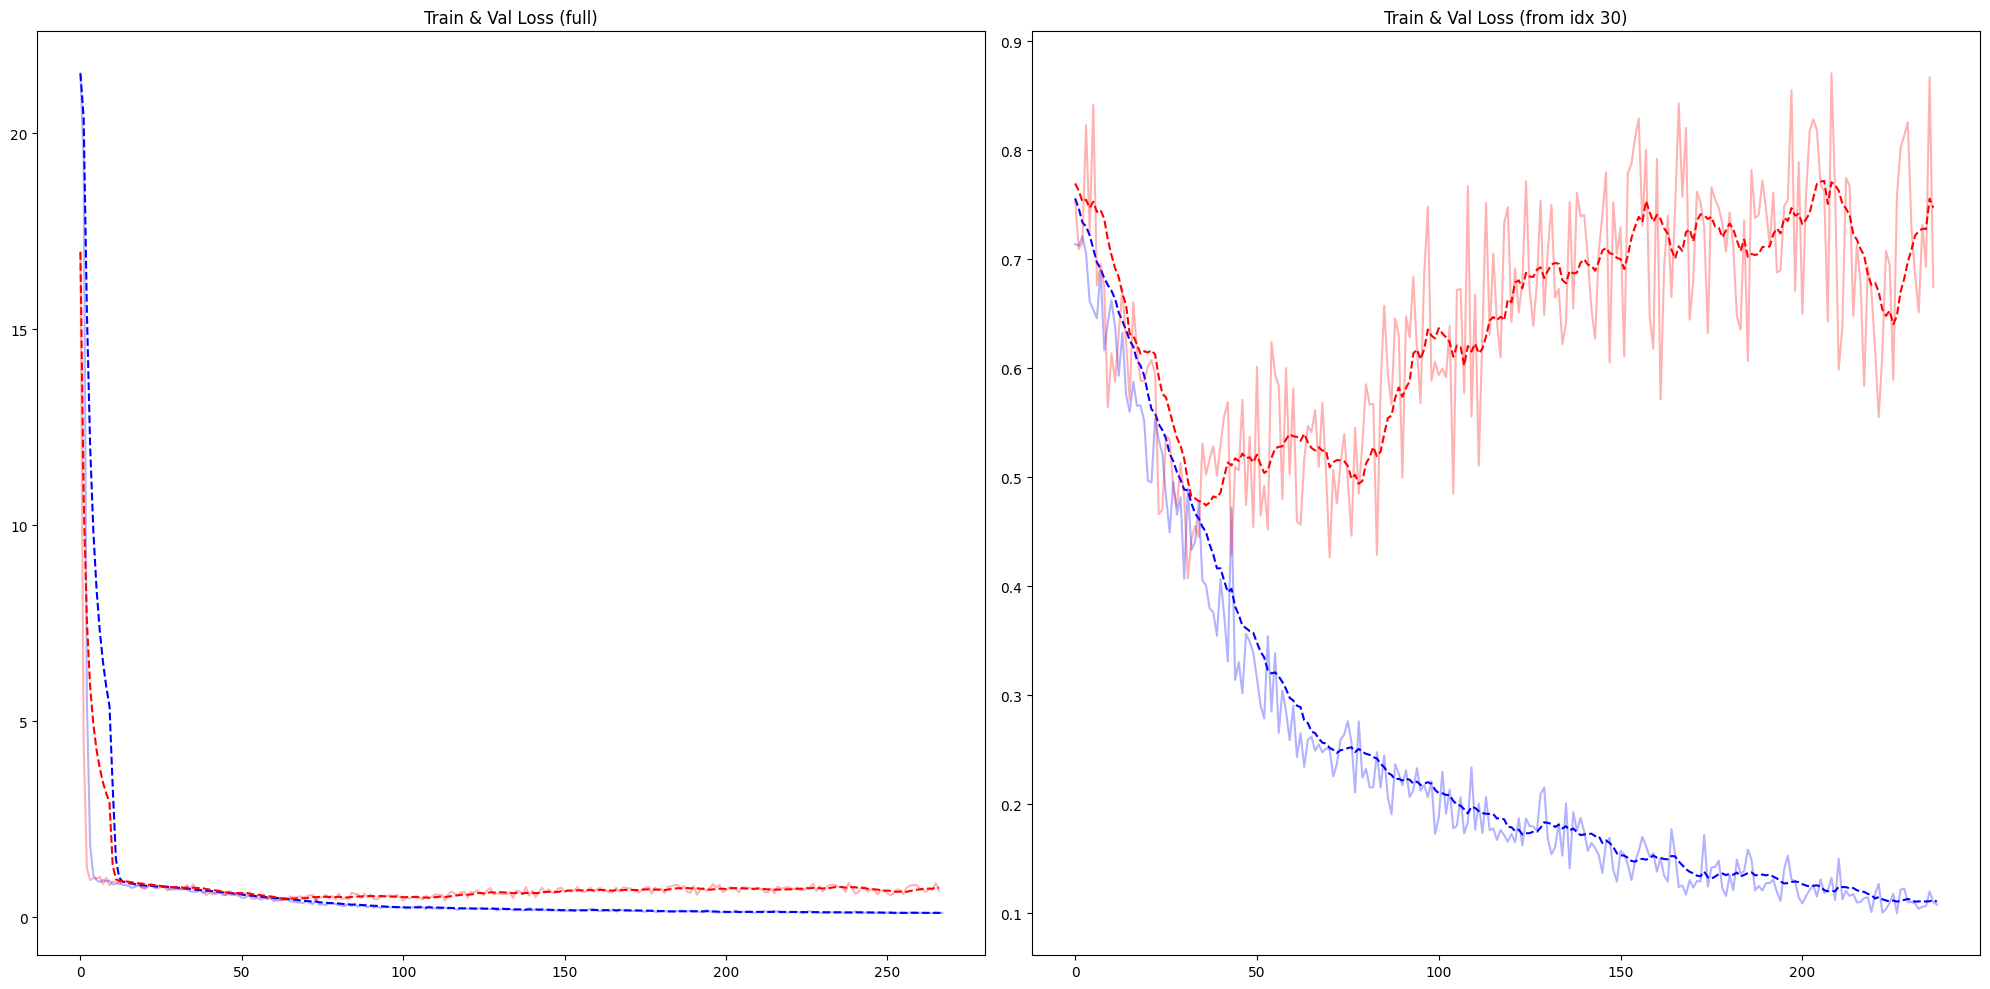

 77%|███████▋  | 687/889 [00:47<00:13, 14.47it/s]


KeyboardInterrupt: 

In [110]:
for epoch in range(n_epochs):
    for i, (imgs, classes) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, classes = imgs.to(device), classes.to(device)

        # get the activation of the layer before the output
        x = resnet_minus_last_layer(imgs)
        x = x.view(x.shape[0], -1)  # flatten the output

        # put it in the sparse autoencoder
        x_hat, z = sparse_auto_encoder(x)

        loss = mse(x_hat, x) + sparsity_penalty(z)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        if i % 10 == 0:
            train_loss_list.append(loss.item())

            # get val loss
            sparse_auto_encoder.eval()
            with torch.no_grad():
                try:
                    imgs, classes = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, classes = next(val_iterator)
                imgs, classes = imgs.to(device), classes.to(device)
                x = resnet_minus_last_layer(imgs)
                x = x.view(x.shape[0], -1)  # flatten the output
                x_hat, z = sparse_auto_encoder(x)
                val_loss = mse(x_hat, x) + sparsity_penalty(z)
                val_loss_list.append(val_loss.item())
            sparse_auto_encoder.train()


    train_loss_list_smoothed = moving_average(train_loss_list)
    val_loss_list_smoothed = moving_average(val_loss_list)

    clear_output(wait=True)  # efface l'ancien plot

    plt.figure(figsize=(20, 10))  # plus grand pour 4 sous-plots

    # 1er plot (train+val loss, full)
    plt.subplot(1, 2, 1)
    plt.plot(train_loss_list, c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
    plt.plot(val_loss_list, c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
    plt.title("Train & Val Loss (full)")

    # 3e plot (train+val loss, from index 30)
    plt.subplot(1, 2, 2)
    plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
    plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
    plt.plot(val_loss_list[30:], c="red", alpha=0.3)
    plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
    plt.title("Train & Val Loss (from idx 30)")

    plt.tight_layout()  # ajuste l'espacement
    plt.show()
